In [1]:
# =============================================================================
# MODULE 5 — Random Forest & Gradient Boosting : Capturer la Non-Linéarité
# =============================================================================
# pip install scikit-learn matplotlib pandas numpy yfinance
# =============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

In [2]:
# =============================================================================
# 1. DONNÉES
# =============================================================================
# Option A — Données réelles (recommandé)
import yfinance as yf
spx = yf.download("^GSPC", start="2000-01-01", end="2024-12-31", auto_adjust=True)
vix = yf.download("^VIX",  start="2000-01-01", end="2024-12-31", auto_adjust=True)
spx_close = spx['Close'].squeeze()
vix_close = vix['Close'].squeeze()
log_ret     = np.log(spx_close / spx_close.shift(1))
realized_vol = log_ret.rolling(21).std() * np.sqrt(252) * 100
df = pd.DataFrame({'VIX': vix_close, 'RealizedVol': realized_vol}).dropna()
print(f"Données : {len(df)} observations ({df.index[0].date()} → {df.index[-1].date()})")

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed

Données : 6267 observations (2000-02-02 → 2024-12-30)


In [3]:
# =============================================================================
# 2. FEATURE ENGINEERING — LAGS + FEATURES NON-LINÉAIRES
# =============================================================================
# Lags VIX (1 à 21 jours)
for k in range(1, 22):
    df[f'VIX_lag{k}']  = df['VIX'].shift(k)
    df[f'DVIX_lag{k}'] = df['VIX'].diff(1).shift(k)

# Features non-linéaires — ce que OLS ne peut pas faire seul
df['VIX_sq']      = df['VIX_lag1'] ** 2              # convexité
df['VIX_sqrt']    = np.sqrt(df['VIX_lag1'].clip(0))  # relation racine carrée
df['VIX_log']     = np.log(df['VIX_lag1'].clip(1))   # relation logarithmique
df['VIX_high']    = (df['VIX_lag1'] > 30).astype(float)   # régime stress
df['VIX_extreme'] = (df['VIX_lag1'] > 50).astype(float)   # régime crise
df['VIX_range5']  = df['VIX_lag1'] - df['VIX_lag5']       # momentum 5j
df['VIX_range21'] = df['VIX_lag1'] - df['VIX_lag21']      # momentum 21j

df = df.dropna()
print(f"Shape après feature engineering : {df.shape}")

# Définition des sets de features
features_linear = ['VIX_lag1', 'VIX_lag5', 'VIX_lag21', 'DVIX_lag1']

features_tree = (
    [f'VIX_lag{k}'  for k in range(1, 22)] +
    [f'DVIX_lag{k}' for k in range(1, 22)] +
    ['VIX_sq', 'VIX_sqrt', 'VIX_log',
     'VIX_high', 'VIX_extreme', 'VIX_range5', 'VIX_range21']
)
print(f"Features linéaires : {len(features_linear)}")
print(f"Features arbres    : {len(features_tree)}")

Shape après feature engineering : (6245, 51)
Features linéaires : 4
Features arbres    : 49


In [4]:
# =============================================================================
# 3. TRAIN / TEST SPLIT (chronologique 80/20)
# =============================================================================
X_lin  = df[features_linear].values
X_tree = df[features_tree].values
y      = df['RealizedVol'].values

split_idx  = int(len(df) * 0.80)
split_date = df.index[split_idx]

Xtr_lin,  Xte_lin  = X_lin[:split_idx],  X_lin[split_idx:]
Xtr_tree, Xte_tree = X_tree[:split_idx], X_tree[split_idx:]
ytr, yte = y[:split_idx], y[split_idx:]
dates_test = df.index[split_idx:]

print(f"\nTrain : {len(ytr)} obs → {split_date.date()}")
print(f"Test  : {len(yte)} obs → {df.index[-1].date()}")

# NOTE : pas de StandardScaler pour RF/GBM — les arbres n'en ont pas besoin !
# StandardScaler reste utile pour OLS et comparaison


Train : 4996 obs → 2020-01-14
Test  : 1249 obs → 2024-12-30


In [5]:
# =============================================================================
# 4. MODÈLE BASELINE — OLS
# =============================================================================
print("\n=== OLS Baseline ===")
sc = StandardScaler().fit(Xtr_lin)
ols = LinearRegression().fit(sc.transform(Xtr_lin), ytr)
y_ols_tr = ols.predict(sc.transform(Xtr_lin))
y_ols_te = ols.predict(sc.transform(Xte_lin))
r2_ols_tr = r2_score(ytr, y_ols_tr)
r2_ols_te = r2_score(yte, y_ols_te)
print(f"OLS : Train={r2_ols_tr:.4f}  Test={r2_ols_te:.4f}  GAP={r2_ols_tr-r2_ols_te:.4f}")


=== OLS Baseline ===
OLS : Train=0.8478  Test=0.7624  GAP=0.0854


In [6]:
# =============================================================================
# 5. RANDOM FOREST
# =============================================================================
print("\n=== Random Forest ===")
rf = RandomForestRegressor(
    n_estimators     = 300,   # nombre d'arbres
    max_depth        = 8,     # profondeur max par arbre
    min_samples_leaf = 20,    # régularisation : feuille = au moins 20 obs
    max_features     = 'sqrt',# sqrt(p) features testées par nœud
    random_state     = 42,
    n_jobs           = -1     # tous les CPU en parallèle
)
rf.fit(Xtr_tree, ytr)
y_rf_tr = rf.predict(Xtr_tree)
y_rf_te = rf.predict(Xte_tree)
r2_rf_tr = r2_score(ytr, y_rf_tr)
r2_rf_te = r2_score(yte, y_rf_te)
rmse_rf  = np.sqrt(mean_squared_error(yte, y_rf_te))
print(f"RF  : Train={r2_rf_tr:.4f}  Test={r2_rf_te:.4f}  GAP={r2_rf_tr-r2_rf_te:.4f}  RMSE={rmse_rf:.3f}")

# Feature importance RF
rf_importance = pd.Series(rf.feature_importances_, index=features_tree)
print("\nTop 10 features (RF) :")
print(rf_importance.sort_values(ascending=False).head(10).round(4).to_string())


=== Random Forest ===
RF  : Train=0.9156  Test=0.8265  GAP=0.0890  RMSE=5.104

Top 10 features (RF) :
VIX_lag3    0.1029
VIX_lag5    0.0982
VIX_lag6    0.0905
VIX_lag7    0.0880
VIX_lag2    0.0796
VIX_lag4    0.0699
VIX_lag8    0.0685
VIX_sq      0.0541
VIX_lag9    0.0505
VIX_log     0.0469


In [7]:

# =============================================================================
# 6. GRADIENT BOOSTING
# =============================================================================
print("\n=== Gradient Boosting ===")
gb = GradientBoostingRegressor(
    n_estimators     = 500,   # nombre d'itérations
    learning_rate    = 0.05,  # pas de correction à chaque itération
    max_depth        = 4,     # arbres peu profonds = stumps
    min_samples_leaf = 20,    # régularisation
    subsample        = 0.8,   # stochastic GBM : 80% des données par itération
    random_state     = 42
)
gb.fit(Xtr_tree, ytr)
y_gb_tr = gb.predict(Xtr_tree)
y_gb_te = gb.predict(Xte_tree)
r2_gb_tr = r2_score(ytr, y_gb_tr)
r2_gb_te = r2_score(yte, y_gb_te)
rmse_gb  = np.sqrt(mean_squared_error(yte, y_gb_te))
print(f"GBM : Train={r2_gb_tr:.4f}  Test={r2_gb_te:.4f}  GAP={r2_gb_tr-r2_gb_te:.4f}  RMSE={rmse_gb:.3f}")

gb_importance = pd.Series(gb.feature_importances_, index=features_tree)
print("\nTop 10 features (GBM) :")
print(gb_importance.sort_values(ascending=False).head(10).round(4).to_string())


=== Gradient Boosting ===
GBM : Train=0.9760  Test=0.8470  GAP=0.1290  RMSE=4.794

Top 10 features (GBM) :
VIX_lag2     0.1582
VIX_lag3     0.1438
VIX_lag4     0.1368
VIX_lag5     0.0921
VIX_lag6     0.0872
VIX_lag7     0.0865
VIX_lag8     0.0656
VIX_log      0.0283
VIX_lag10    0.0274
VIX_lag9     0.0243


In [8]:
# =============================================================================
# 7. RÉSUMÉ
# =============================================================================
print("\n" + "="*65)
print("RÉSUMÉ MODULE 5")
print("="*65)
print(f"{'Modèle':<20} {'Train R²':>10} {'Test R²':>10} {'GAP':>8} {'RMSE':>8}")
print("-"*58)
for lbl, tr, te, rmse in [
    ("OLS linéaire",    r2_ols_tr, r2_ols_te, np.sqrt(mean_squared_error(yte, y_ols_te))),
    ("Random Forest",   r2_rf_tr,  r2_rf_te,  rmse_rf),
    ("Gradient Boost.", r2_gb_tr,  r2_gb_te,  rmse_gb),
]:
    flag = "⚠️" if tr - te > 0.05 else "✅"
    print(f"{lbl:<20} {tr:>10.4f} {te:>10.4f} {tr-te:>8.4f} {rmse:>8.3f} {flag}")


RÉSUMÉ MODULE 5
Modèle                 Train R²    Test R²      GAP     RMSE
----------------------------------------------------------
OLS linéaire             0.8478     0.7624   0.0854    5.973 ⚠️
Random Forest            0.9156     0.8265   0.0890    5.104 ⚠️
Gradient Boost.          0.9760     0.8470   0.1290    4.794 ⚠️


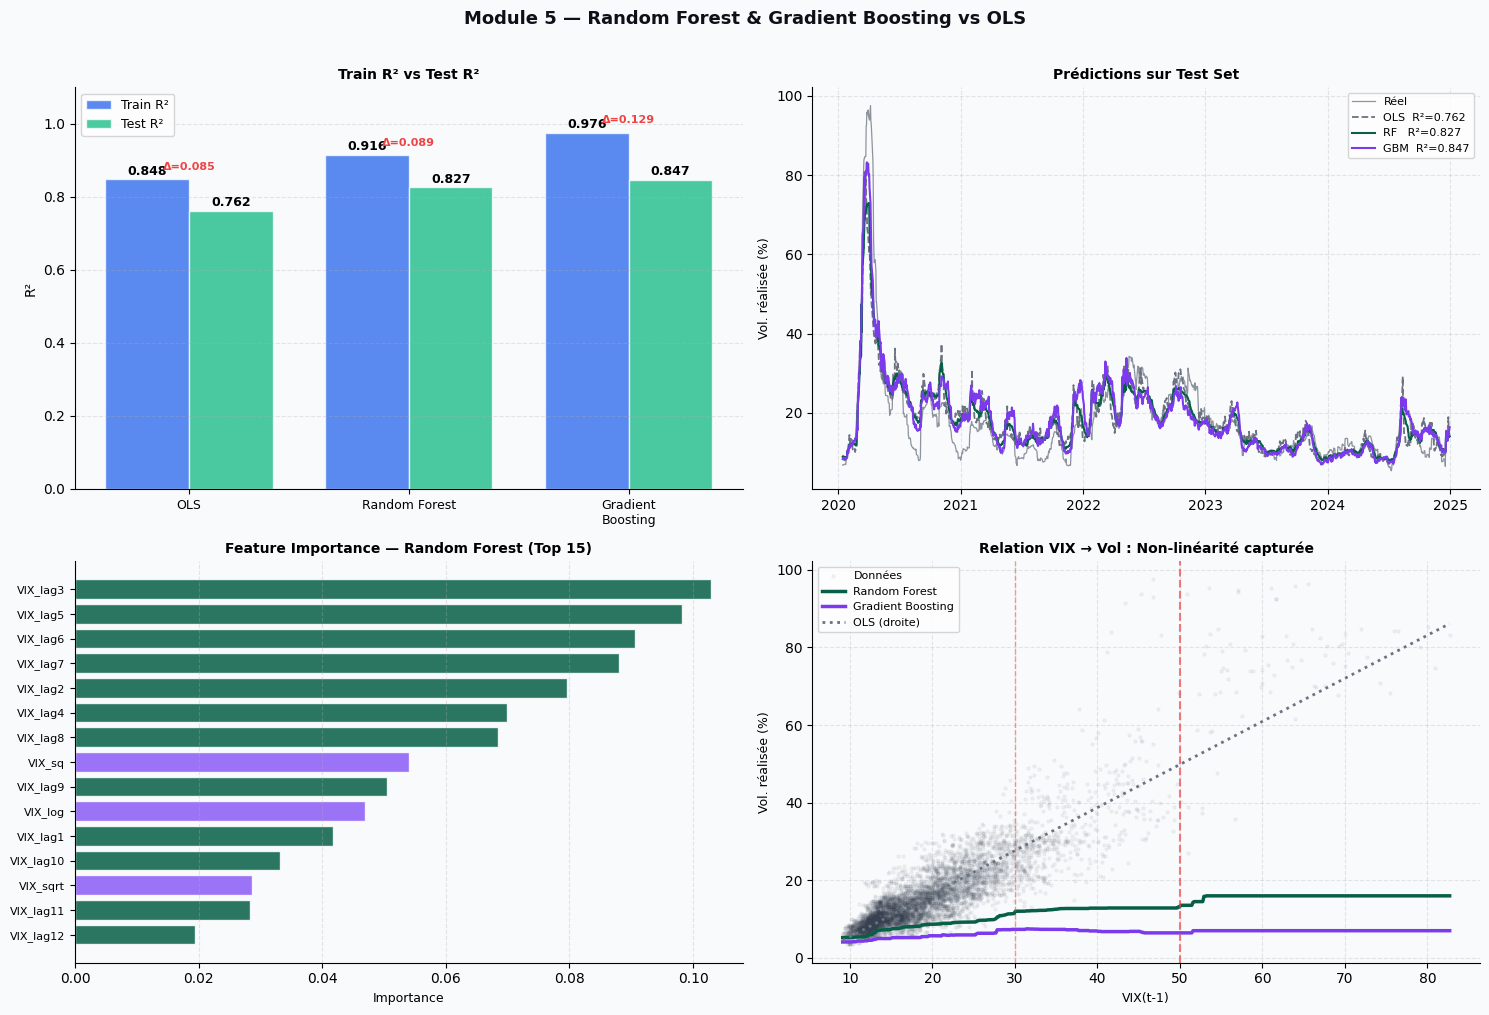


Graphique sauvegardé : module5_results.png


In [9]:
# =============================================================================
# 8. VISUALISATIONS
# =============================================================================
PLT_BG = '#F8FAFC'
fig, axes = plt.subplots(2, 2, figsize=(15, 10), facecolor=PLT_BG)
fig.suptitle('Module 5 — Random Forest & Gradient Boosting vs OLS',
             fontsize=13, fontweight='bold', color='#0D1117', y=1.01)

# ── Fig 1 : Comparaison R² ────────────────────
ax = axes[0, 0]
models = ['OLS', 'Random Forest', 'Gradient\nBoosting']
tr_r2s = [r2_ols_tr, r2_rf_tr, r2_gb_tr]
te_r2s = [r2_ols_te, r2_rf_te, r2_gb_te]
x = np.arange(3); w = 0.38
b1 = ax.bar(x-w/2, tr_r2s, w, color='#2563EB', alpha=0.75, label='Train R²', edgecolor='white')
b2 = ax.bar(x+w/2, te_r2s, w, color='#10B981', alpha=0.75, label='Test R²',  edgecolor='white')
for bar, val in zip(list(b1)+list(b2), tr_r2s+te_r2s):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.004,
            f'{val:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
for i, (tr, te) in enumerate(zip(tr_r2s, te_r2s)):
    ax.text(x[i], max(tr,te)+0.025, f'Δ={tr-te:.3f}',
            ha='center', fontsize=8, color='#EF4444', fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels(models, fontsize=9)
ax.set_ylabel('R²', fontsize=10); ax.set_ylim(0, 1.1)
ax.set_title('Train R² vs Test R²', fontsize=10, fontweight='bold')
ax.legend(fontsize=9); ax.set_facecolor(PLT_BG)
ax.grid(True, alpha=0.3, linestyle='--', axis='y')
ax.spines[['top','right']].set_visible(False)

# ── Fig 2 : Prédictions test set ──────────────
ax = axes[0, 1]
ax.plot(dates_test, yte, color='#374151', lw=0.9, alpha=0.55, label='Réel')
ax.plot(dates_test, y_ols_te, color='#6B7280', lw=1.3, linestyle='--',
        label=f'OLS  R²={r2_ols_te:.3f}')
ax.plot(dates_test, y_rf_te, color='#065F46', lw=1.5,
        label=f'RF   R²={r2_rf_te:.3f}')
ax.plot(dates_test, y_gb_te, color='#7C3AED', lw=1.5,
        label=f'GBM  R²={r2_gb_te:.3f}')
ax.set_title('Prédictions sur Test Set', fontsize=10, fontweight='bold')
ax.set_ylabel('Vol. réalisée (%)', fontsize=9)
ax.legend(fontsize=8); ax.set_facecolor(PLT_BG)
ax.grid(True, alpha=0.3, linestyle='--')
ax.spines[['top','right']].set_visible(False)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

# ── Fig 3 : Feature Importance RF ─────────────
ax = axes[1, 0]
top15 = rf_importance.sort_values(ascending=False).head(15)
bar_cols = ['#065F46' if 'lag' in f and 'DVIX' not in f else
            '#F59E0B' if 'DVIX' in f else '#8B5CF6' for f in top15.index]
ax.barh(range(len(top15)), top15.values[::-1], color=bar_cols[::-1],
        alpha=0.85, edgecolor='white')
ax.set_yticks(range(len(top15)))
ax.set_yticklabels(top15.index[::-1], fontsize=8)
ax.set_xlabel('Importance', fontsize=9)
ax.set_title('Feature Importance — Random Forest (Top 15)', fontsize=10, fontweight='bold')
ax.set_facecolor(PLT_BG); ax.grid(True, alpha=0.3, linestyle='--', axis='x')
ax.spines[['top','right']].set_visible(False)

# ── Fig 4 : Relation non-linéaire ─────────────
ax = axes[1, 1]
vix_range = np.linspace(df['VIX_lag1'].min(), df['VIX_lag1'].max(), 500)
ax.scatter(df['VIX_lag1'], df['RealizedVol'], alpha=0.05, s=5,
           color='#374151', label='Données')

# Prédiction modèles sur gamme de VIX
X_demo = np.zeros((500, len(features_tree)))
for j, feat in enumerate(features_tree):
    if feat == 'VIX_lag1':    X_demo[:,j] = vix_range
    elif feat == 'VIX_sq':    X_demo[:,j] = vix_range**2
    elif feat == 'VIX_sqrt':  X_demo[:,j] = np.sqrt(np.clip(vix_range,0,None))
    elif feat == 'VIX_log':   X_demo[:,j] = np.log(np.clip(vix_range,1,None))
    elif feat == 'VIX_high':  X_demo[:,j] = (vix_range>30).astype(float)
    elif feat == 'VIX_extreme': X_demo[:,j] = (vix_range>50).astype(float)

ax.plot(vix_range, rf.predict(X_demo), color='#065F46', lw=2.5, label='Random Forest')
ax.plot(vix_range, gb.predict(X_demo), color='#7C3AED', lw=2.5, label='Gradient Boosting')

# OLS approx
ols_line = np.polyval(np.polyfit(df['VIX_lag1'], df['RealizedVol'], 1), vix_range)
ax.plot(vix_range, ols_line, color='#6B7280', lw=2, linestyle=':', label='OLS (droite)')

ax.axvline(30, color='#EF4444', lw=1, linestyle='--', alpha=0.5)
ax.axvline(50, color='#EF4444', lw=1.5, linestyle='--', alpha=0.7)
ax.set_xlabel('VIX(t-1)', fontsize=9); ax.set_ylabel('Vol. réalisée (%)', fontsize=9)
ax.set_title('Relation VIX → Vol : Non-linéarité capturée', fontsize=10, fontweight='bold')
ax.legend(fontsize=8); ax.set_facecolor(PLT_BG)
ax.grid(True, alpha=0.3, linestyle='--')
ax.spines[['top','right']].set_visible(False)

plt.tight_layout()
plt.savefig('module5_results.png', dpi=150, bbox_inches='tight')
plt.show()
print("\nGraphique sauvegardé : module5_results.png")